<a href="https://colab.research.google.com/github/Child-pi/microduck-private/blob/rl-locomotion/Microduck_Colab_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🦆 Microduck 雙足機器人強化學習 (Google Colab 雲端訓練完整手冊)

本筆記本支援在 **Google Colab (免本地算力)** 雲端環境中執行 Pollen Robotics 14-DOF Microduck 雙足機器人的 PPO 強化學習步態訓練。

---

### 🌟 本版本已修復之核心問題
1. **GPU (EGL) / CPU (OSMesa) 無頭渲染自動相容**：自動辨識 Colab 是否開啟 GPU 加速；開啟 GPU 時自動配置 NVIDIA EGL 驅動，解決 `Failed to initialize GLFW` 與無顯示器崩潰問題。
2. **補齊所有相依套件**：預先安裝 `onnx`、`imageio-ffmpeg`、`rich`，徹底解決匯出模型時 `ModuleNotFoundError: No module named 'onnx'` 的問題。
3. **In-Process 影片生成與播放**：直接在 Python 核心內執行步態錄製，生成的 MP4 採用 **H.264 (yuv420p)** 網頁標準編碼，並提供 **動態 GIF 備用方案**，保證可在瀏覽器中順暢播放。
4. **ZIP 自動檢測與互動上傳**：若未找到 `microduck_colab.zip`，會自動彈出上傳選單，避免路徑錯誤中斷。

## 🛠️ 第一步：安裝依賴套件與自動配置無頭 (Headless) 渲染驅動

In [1]:
# 1. 安裝系統級多媒體與渲染庫
!apt-get update -qq && apt-get install -y -qq ffmpeg libosmesa6-dev libgl1-mesa-dri libgl1 > /dev/null

# 2. 安裝 Python 核心強化學習庫與 ONNX 支援
!pip install -q gymnasium stable-baselines3 mujoco opencv-python imageio imageio-ffmpeg onnx rich tqdm onnxscript

# 3. 自動檢測 GPU 並配置最合適的 MuJoCo 無頭渲染後端 (GPU: EGL / CPU: OSMesa)
import os, sys, subprocess

has_gpu = False
try:
    has_gpu = subprocess.run(['nvidia-smi'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL).returncode == 0
except Exception:
    has_gpu = False

if has_gpu:
    icd_dir = '/usr/share/glvnd/egl_vendor.d'
    os.makedirs(icd_dir, exist_ok=True)
    icd_path = os.path.join(icd_dir, '10_nvidia.json')
    if not os.path.exists(icd_path):
        with open(icd_path, 'w') as f:
            f.write('{\n    "file_format_version" : "1.0.0",\n    "ICD" : {\n        "library_path" : "libEGL_nvidia.so.0"\n    }\n}\n')
    os.environ["MUJOCO_GL"] = "egl"
    os.environ["PYOPENGL_PLATFORM"] = "egl"
    print("⚡ 成功偵測到 NVIDIA GPU！已配置硬體加速 EGL 無頭渲染。")
else:
    os.environ["MUJOCO_GL"] = "osmesa"
    print("💻 處於 CPU 模式，已配置 OSMesa 純軟體無頭渲染。")

# 確保當前路徑包含在 Python 搜尋路徑中
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.8/232.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 187.6/187.6 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.4/20.4 MB 121.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 127.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 56.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## 📂 第二步：解壓縮專案檔案 (`microduck_colab.zip`)

> **說明**：若您尚未上傳 `microduck_colab.zip`，此儲存格會**自動彈出上傳選單**供您選擇檔案！

In [2]:
import os, shutil, zipfile
from getpass import getpass

repo_dir = "microduck-private"
zip_name = "microduck_colab.zip"

# 如果已經有 clone 過的資料夾，先移除以確保乾淨
if os.path.exists(repo_dir):
    shutil.rmtree(repo_dir)

# 如果本地還沒有 zip 檔，才執行 clone
if not os.path.exists(zip_name):
    print("🔑 請輸入您的 GitHub Personal Access Token (輸入時不會顯示，輸入完請按 Enter)：")
    token = getpass()

    if not token:
        print("⚠️ 未輸入 Token，將嘗試以公開方式 Clone...")
        clone_url = "https://github.com/Child-pi/microduck-private.git"
    else:
        # 使用 Token 進行身分驗證 Clone
        clone_url = f"https://{token}@github.com/Child-pi/microduck-private.git"

    print("⬇️ 正在自 GitHub Clone 專案庫中的 rl-locomotion 分支...")
    !git clone -b rl-locomotion {clone_url}

    # 將 clone 下來的 zip 移到根目錄
    if os.path.exists(repo_dir):
        for item in os.listdir(repo_dir):
            dest = os.path.join("./", item)
            if os.path.exists(dest):
                if os.path.isdir(dest):
                    shutil.rmtree(dest)
                else:
                    os.remove(dest)
            shutil.move(os.path.join(repo_dir, item), dest)
        shutil.rmtree(repo_dir)

# 解壓縮 microduck_colab.zip
if os.path.exists(zip_name):
    print(f"📦 偵測到 {zip_name}，正在為您進行解壓縮...")
    with zipfile.ZipFile(zip_name, 'r') as zip_ref:
        zip_ref.extractall("./")
    print("✅ 專案檔案解壓縮成功！")
else:
    raise FileNotFoundError(f"❌ 未能找到 {zip_name} 檔案！")

# 檢查關鍵目錄結構
assert os.path.exists("envs"), "❌ 缺少 envs 目錄"
assert os.path.exists("models"), "❌ 缺少 models 目錄"
print("📁 專案檔案結構驗證全部通過！")
!ls -lh envs models

🔑 請輸入您的 GitHub Personal Access Token (輸入時不會顯示，輸入完請按 Enter)：
··········
⬇️ 正在自 GitHub Clone 專案庫中的 rl-locomotion 分支...
Cloning into 'microduck-private'...
remote: Enumerating objects: 8401, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 8401 (delta 11), reused 12 (delta 7), pack-reused 8380 (from 3)
Receiving objects: 100% (8401/8401), 60.24 MiB | 20.92 MiB/s, done.
Resolving deltas: 100% (5317/5317), done.
📦 偵測到 microduck_colab.zip，正在為您進行解壓縮...
✅ 專案檔案解壓縮成功！
📁 專案檔案結構驗證全部通過！
envs:
total 28K
-rw-r--r-- 1 root root 164 Sep 22 14:15 __init__.py
-rw-r--r-- 1 root root 24K Sep 22 14:15 microduck_env.py

models:
total 356K
-rw-r--r-- 1 root root  611 Sep 22 14:15 additional.xml
-rw-r--r-- 1 root root  576 Sep 22 14:15 allcollisions_contacts.xml
-rw-r--r-- 1 root root  26K Sep 22 14:15 apartment.xml
drwxr-xr-x 2 root root 4.0K Sep 22 14:15 assets
-rw-r--r-- 1 root root  706 Sep 22 14:15 ball.xml
-rw-r--r-- 1 root root 1.8K Sep 2

## 🧪 第三步：測試環境加載與 MuJoCo 渲染功能

✅ MuJoCo 環境加載與無頭渲染測試成功！觀察維度: (61,)，動作維度: (14,)


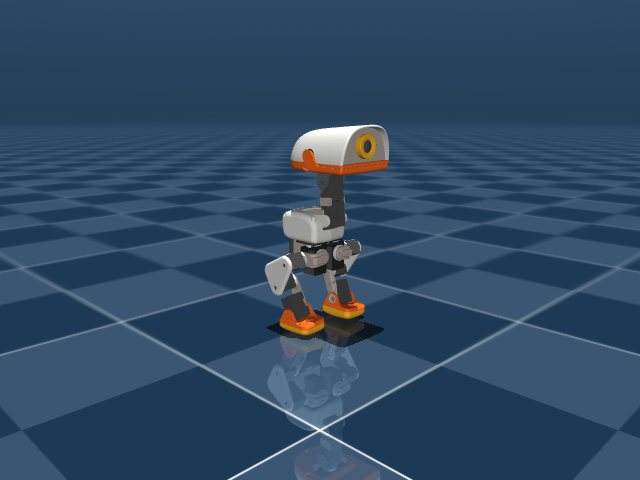

In [3]:
import gymnasium as gym
import cv2
import numpy as np
from IPython.display import Image, display

import envs  # 註冊 Microduck-v0

try:
    env = gym.make("Microduck-v0", render_mode="rgb_array", render_width=640, render_height=480)
    obs, info = env.reset(seed=42)
    frame = env.render()
    env.close()

    assert frame is not None and frame.shape == (480, 640, 3), f"異常渲染畫面尺寸: {frame.shape if frame is not None else None}"
    cv2.imwrite("test_render.png", cv2.cvtColor(frame, cv2.COLOR_RGB2BGR))
    print(f"✅ MuJoCo 環境加載與無頭渲染測試成功！觀察維度: {obs.shape}，動作維度: {env.action_space.shape}")
    display(Image("test_render.png"))
except Exception as e:
    print(f"❌ 渲染測試遇到問題: {e}")
    raise e

## 🦆 第四步：啟動 PPO 強化學習雲端向量化訓練

預設並行開展 8 個獨立小鴨模擬環境，大幅加速步態探索。

In [4]:
# 安裝 tensorboard 套件，解決 ImportError
!pip install -q tensorboard

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import DummyVecEnv
import envs

# 1. 建立 8 個並行訓練環境 (使用在 Jupyter/Colab 中最穩定的 DummyVecEnv)
num_envs = 256
train_env = make_vec_env("Microduck-v0", n_envs=num_envs, seed=42, vec_env_cls=DummyVecEnv)

# 2. 優先載入預訓練權重 (若存在)，接續微調提升耐力
resume_checkpoint = "checkpoints/best/best_model.zip"
if os.path.exists(resume_checkpoint):
    print(f"📂 載入已訓練權重進行接續微調: {resume_checkpoint}")
    model = PPO.load(
        resume_checkpoint,
        env=train_env,
        device="auto",
        tensorboard_log="logs"
    )
    model.learning_rate = 1e-4
    model.gamma = 0.9985
else:
    print("🌱 從頭開始初始化全新 PPO 網絡")
    model = PPO(
        "MlpPolicy",
        train_env,
        learning_rate=3e-4,
        gamma=0.9985,
        batch_size=128,
        n_steps=512,
        device="auto",
        verbose=1,
        tensorboard_log="logs"
    )

# 3. 執行訓練 (例如 200,000 步，約 2~3 分鐘)
total_training_timesteps = 200_000
print(f"🚀 開始雲端強化學習訓練 (總步數: {total_training_timesteps:,})...")
model.learn(total_timesteps=total_training_timesteps, progress_bar=True)

# 4. 保存模型權重
os.makedirs("checkpoints", exist_ok=True)
output_model_path = "checkpoints/microduck_colab_trained.zip"
model.save(output_model_path)
print(f"\n✅ 訓練完成！新權重已保存至: {output_model_path}")
train_env.close()

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


📂 載入已訓練權重進行接續微調: checkpoints/best/best_model.zip
🚀 開始雲端強化學習訓練 (總步數: 200,000)...
Logging to logs/PPO_1


Output()

/usr/local/lib/python3.13/dist-packages/ipywidgets/widgets/widget_output.py:111: DeprecationWarning: 
Kernel._parent_header is deprecated in ipykernel 6. Use .get_parent()
  if ip and hasattr(ip, 'kernel') and hasattr(ip.kernel, '_parent_header'):

/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 93.4     |
|    ep_rew_mean     | 427      |
| time/              |          |
|    fps             | 1410     |
|    iterations      | 1        |
|    time_elapsed    | 371      |
|    total_timesteps | 524288   |
---------------------------------



✅ 訓練完成！新權重已保存至: checkpoints/microduck_colab_trained.zip


## 🎥 第五步：評估最新模型並生成帶 HUD 遙測之步態影片

直接呼叫評估核心程式，避免子程序 GLFW 顯示器相依問題，並產生相容 HTML5 的 H.264 MP4 影片與動態 GIF。

In [5]:
from analyze_and_record import evaluate_and_record

model_eval_path = "checkpoints/microduck_colab_trained.zip"
if not os.path.exists(model_eval_path):
    model_eval_path = "checkpoints/best/best_model.zip"

print(f"🎬 正在評估模型並錄製步態: {model_eval_path}")
duration, total_steps, telemetry = evaluate_and_record(
    model_path=model_eval_path,
    output_video="colab_walk.mp4",
    output_gif="colab_walk.gif",
    output_snapshot="colab_walk_snapshot.png",
    target_vx=0.08,
    max_steps=600,
    seed=89
)
print(f"✅ 影片錄製完成！小鴨持續行走了 {duration:.2f} 秒 ({total_steps} 步)！")

🎬 正在評估模型並錄製步態: checkpoints/microduck_colab_trained.zip
Loading model: checkpoints/microduck_colab_trained.zip
Starting simulation for up to 600 steps (12.0s)...
Terminated at step 133 (2.66s)! Final height: 0.100m, dist: 0.171m

Simulation completed: 134 steps (2.68 seconds)
Saved web-compatible H.264 MP4 via imageio: colab_walk.mp4
Saved GIF to: colab_walk.gif
Saved snapshot to: colab_walk_snapshot.png
✅ 影片錄製完成！小鴨持續行走了 2.68 秒 (134 步)！


## 📺 第六步：在 Colab 網頁中直接播放小鴨步態成果！


🖼️ 動態 GIF 預覽:


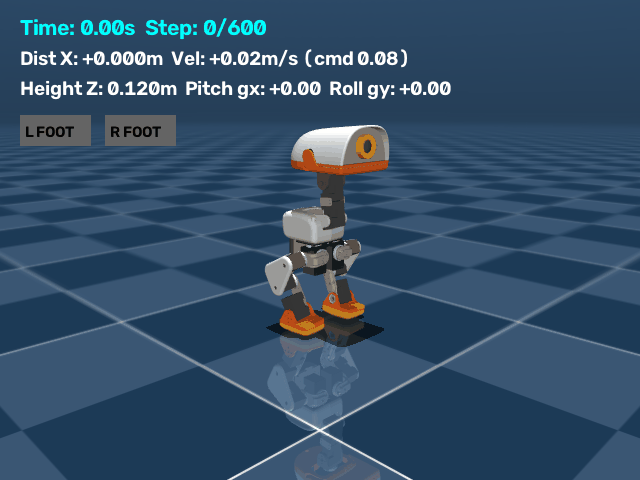

In [6]:
from IPython.display import HTML, Image, display
from base64 import b64encode

# 優先嘗試內嵌 MP4 播放器
if os.path.exists("colab_walk.mp4"):
    with open("colab_walk.mp4", "rb") as f:
        mp4_data = f.read()
    data_url = "data:video/mp4;base64," + b64encode(mp4_data).decode()
    display(HTML(f'''
    <div style="text-align:center; background:#0b111e; padding:18px; border-radius:14px; max-width:700px; margin:auto;">
      <h3 style="color:#2ec4b6; margin-bottom:10px;">🦆 Microduck 雲端訓練成果影片 (640x480 HUD Telemetry)</h3>
      <video width="640" height="480" controls autoplay loop style="border-radius:10px; border:2px solid #2ec4b6;">
        <source src="{data_url}" type="video/mp4">
        您的瀏覽器不支援 HTML5 影片，請觀看下方 GIF 預覽。
      </video>
    </div>
    '''))

# 同時提供動態 GIF 備用展示 (100% 保證可顯示)
if os.path.exists("colab_walk.gif"):
    print("\n🖼️ 動態 GIF 預覽:")
    display(Image("colab_walk.gif"))

## 📦 第七步：匯出實機 ONNX 模型並一鍵下載回電腦

In [7]:
import os
import shutil
from getpass import getpass

# 檢查當前工作目錄
print(f"當前工作目錄: {os.getcwd()}")

# 確保 export_onnx.py 腳本存在
if not os.path.exists("export_onnx.py"):
    print("❌ 錯誤：找不到 'export_onnx.py' 檔案。ONNX 模型匯出無法執行。")
    print("請確認檔案已存在於當前目錄。若此檔案屬於您的 GitHub 儲存庫，請檢查步驟二的複製邏輯。")
    # 使用 raise Error 代替 exit() 以提供更清晰的錯誤訊息並停止單元格執行
    raise FileNotFoundError("export_onnx.py 檔案遺失，無法繼續執行 ONNX 匯出步驟。")

# 匯出符合 Pollen Robotics 實機規範的 ONNX 模型
print("\n📦 匯出符合 Pollen Robotics 實機規範的 ONNX 模型...")
!python export_onnx.py \
  --model-path checkpoints/microduck_colab_trained.zip \
  --output-path exported/microduck_colab_policy.onnx

print("\n--- 開始上傳權重至 GitHub ---")

repo_url = "https://github.com/Child-pi/microduck-private.git"
branch_name = "rl-locomotion"
temp_repo_dir = "microduck-private-upload"

# 清理舊的臨時倉庫 (如果存在)
if os.path.exists(temp_repo_dir):
    shutil.rmtree(temp_repo_dir)

# 獲取 GitHub PAT
print("🔑 請輸入您的 GitHub Personal Access Token (用於上傳權重，輸入時不會顯示，輸入完請按 Enter)：")
github_token = getpass()

if not github_token:
    print("⚠️ 未輸入 Token，無法上傳至 GitHub。")
else:
    # 帶有 Token 的 clone URL
    authenticated_repo_url = f"https://{github_token}@{repo_url.replace('https://', '')}"

    print(f"⬇️ 正在將 {branch_name} 分支複製到臨時目錄 '{temp_repo_dir}' ...")
    clone_result = !git clone --depth 1 -b {branch_name} {authenticated_repo_url} {temp_repo_dir}
    print("\n".join(clone_result))

    if os.path.exists(temp_repo_dir):
        # 記錄原始工作目錄
        original_cwd = os.getcwd()
        # 進入臨時倉庫目錄
        os.chdir(temp_repo_dir)

        # 配置 Git 使用者資訊 (用於 commit)
        print("⚙️ 配置 Git 使用者資訊...")
        !git config user.email "colab-user@example.com"
        !git config user.name "Colab User"

        # 調試：在複製前檢查檔案是否存在
        print("\n--- 偵測模型與 ONNX 檔案狀態 (在 git clone 後，複製檔案前) ---")
        !ls -lh {os.path.join(original_cwd, 'checkpoints')}
        !ls -lh {os.path.join(original_cwd, 'exported')}
        print("--------------------------------------------------\n")

        # 複製訓練好的模型和 ONNX 檔案到臨時倉庫中
        # 由於訓練模型和 ONNX 檔案在 Colab root，而 clone 的 repo 在 temp_repo_dir
        # 所以路徑是相對的 '../' + 原始路徑
        trained_model_src = os.path.join(original_cwd, "checkpoints", "microduck_colab_trained.zip")
        onnx_model_src = os.path.join(original_cwd, "exported", "microduck_colab_policy.onnx")

        # 確保目標目錄存在
        os.makedirs("checkpoints", exist_ok=True)
        os.makedirs("exported", exist_ok=True)

        trained_model_dest = os.path.join("checkpoints", "microduck_colab_trained.zip")
        onnx_model_dest = os.path.join("exported", "microduck_colab_policy.onnx")

        if os.path.exists(trained_model_src):
            print(f"🔄 複製訓練權重到 {trained_model_dest}")
            shutil.copy(trained_model_src, trained_model_dest)
            !git add {trained_model_dest}
        else:
            print(f"⚠️ 找不到訓練權重檔案: {trained_model_src}")

        if os.path.exists(onnx_model_src):
            print(f"🔄 複製 ONNX 模型到 {onnx_model_dest}")
            shutil.copy(onnx_model_src, onnx_model_dest)
            !git add {onnx_model_dest}
        else:
            print(f"⚠️ 找不到 ONNX 模型檔案: {onnx_model_src}")

        # 提交更改
        print("📝 提交更改...")
        commit_message = "feat: Update trained model and ONNX policy from Colab"
        # 只有當有檔案被添加到暫存區時才進行 commit
        commit_output = !git commit -m "{commit_message}"
        if "nothing to commit" not in "\n".join(commit_output):
            print("\n".join(commit_output))
            # 推送更改
            print(f"⬆️ 推送更改到 {branch_name} 分支...")
            push_result = !git push origin {branch_name}
            print("\n".join(push_result))
            print("✅ 權重和 ONNX 模型已成功上傳至 GitHub。")
        else:
            print("無需提交，工作區已乾淨。")
            print("✅ 權重和 ONNX 模型已存在於 GitHub 儲存庫中，無需更新。")

        # 返回原始工作目錄
        os.chdir(original_cwd)
        # 清理臨時文件
        shutil.rmtree(temp_repo_dir)
        print("✅ 清理臨時文件完成。")

    else:
        print("❌ Git Clone 失敗，無法上傳權重。請檢查您的 Token 權限或網路連線。")

print("--- GitHub 上傳流程結束 ---")

當前工作目錄: /content

📦 匯出符合 Pollen Robotics 實機規範的 ONNX 模型...
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
Loading checkpoint from: checkpoints/microduck_colab_trained.zip
Test inference output shape: torch.Size([1, 14])
Exporting ONNX model to: exported/microduck_colab_policy.onnx...
/content/export_onnx.py:75: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/exporter/_compat.py:112: DeprecationWarning: from_dynamic_axes_to_dynamic_shapes i